In [1]:
pip install typesafe-sdk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TYPESAFE_API_KEY"]="apikey_2399dc00e69bb95449599675a5469ab7057_d132ce4419d2bdde34eb4ea7f8cce286aafd3c3875cf1be16fae46db815a18bc"

In [4]:
ticket = """
I purchased the Python course yesterday.

Payment was successfully deducted from my account,
but the course is still locked.

I have an interview tomorrow and urgently need access.

Please resolve this immediately.
"""

In [5]:
from typesafe_sdk import (
    TypeSafeClient,
    Choice,
    Score,
    Noul
)

In [6]:
client = TypeSafeClient()

In [7]:
response = client.system_one(

    state=ticket,

    questions={

        "department": Choice(
            instructions="Which department should handle this ticket?",
            criteria={
                "billing": "Payment, billing, refund or transaction issue",
                "technical": "Platform, application or software issue",
                "sales": "Pricing, purchasing or sales enquiry",
                "academic": "Course content or learning related issue"
            }
        ),

        "frustration": Score(
            instructions="How frustrated does the customer appear?",
            criteria=[
                "Calm",
                "Slightly frustrated",
                "Frustrated",
                "Very frustrated",
                "Extremely angry"
            ]
        ),

        "urgent": Noul(
            instructions="The customer requires urgent attention"
        )

    }

)

In [8]:
print(response)

model='jev-1.13.0' usage=Usage(input_tokens=467, output_tokens=77) answers={'department': ChoiceAnswer(type='choice', choice='technical', confidence=0.41, probabilities={'academic': 0.0, 'billing': 0.43, 'technical': 0.5700000000000001, 'sales': 0.0}), 'frustration': ScoreAnswer(type='score', score=2.32, confidence=0.68, legend={0: 'Calm', 1: 'Slightly frustrated', 2: 'Frustrated', 3: 'Very frustrated', 4: 'Extremely angry'}, probabilities={0: 0.0, 1: 0.03, 2: 0.62, 3: 0.35, 4: 0.0}), 'urgent': NoulAnswer(type='noul', noul=0.96)}


In [9]:
department = response.answers["department"]

print(department.choice)
print(department.confidence)
print(department.probabilities)

technical
0.41
{'academic': 0.0, 'billing': 0.43, 'technical': 0.5700000000000001, 'sales': 0.0}


In [10]:
urgent = response.answers["urgent"]

print(urgent.noul)

0.96


In [11]:
department = response.answers["department"]
urgent = response.answers["urgent"]
frustration = response.answers["frustration"]


if department.confidence < 0.50:

    print("Send to manual triage")

else:

    print(
        f"Routing ticket to: {department.choice}"
    )


if urgent.noul > 0.80:

    print("HIGH PRIORITY")


if frustration.score >= 3:

    print("Notify senior support executive")

Send to manual triage
HIGH PRIORITY


In [12]:
pip install langgraph

Note: you may need to restart the kernel to use updated packages.


In [13]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class AgentState(TypedDict):
    question: str
    route: str
    answer: str

In [14]:
from typesafe_sdk import TypeSafeClient, Choice


client = TypeSafeClient()

In [15]:
def jev_router(state):

    result = client.system_one(

        state=state["question"],

        questions={

            "route": Choice(

                instructions=
                "Which system should handle this request?",

                criteria={

                    "rag":
                    "Question requiring internal knowledge",

                    "direct":
                    "Simple conversational request",

                    "human":
                    "Sensitive or ambiguous request"

                }

            )

        }

    )

    decision = result.answers["route"]

    if decision.confidence < 0.5:
        route = "human"
    else:
        route = decision.choice

    return {
        "route": route
    }

In [16]:
def rag_node(state):

    # retriever.invoke(...)
    # llm.invoke(...)

    return {
        "answer":
        "Answer generated using RAG"
    }


def direct_node(state):

    return {
        "answer":
        "Direct response"
    }


def human_node(state):

    return {
        "answer":
        "Escalated to human"
    }

In [17]:
def route(state):

    return state["route"]

In [18]:
graph = StateGraph(AgentState)

graph.add_node("jev", jev_router)
graph.add_node("rag", rag_node)
graph.add_node("direct", direct_node)
graph.add_node("human", human_node)

graph.add_edge(
    START,
    "jev"
)

graph.add_conditional_edges(

    "jev",

    route,

    {
        "rag": "rag",
        "direct": "direct",
        "human": "human"
    }

)

graph.add_edge("rag", END)
graph.add_edge("direct", END)
graph.add_edge("human", END)

app = graph.compile()

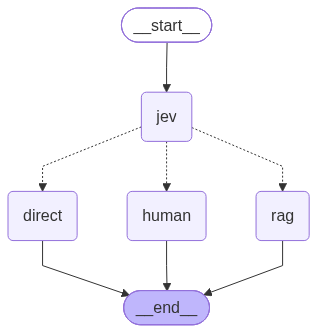

In [19]:
app

In [20]:
app.invoke({
    "question": "what is a euron refund policy"
})

{'question': 'what is a euron refund policy',
 'route': 'human',
 'answer': 'Escalated to human'}

In [21]:
app.invoke({
    "question": "What is data science?"
})

{'question': 'What is data science?',
 'route': 'direct',
 'answer': 'Direct response'}

In [22]:
app.invoke({
    "question": "What is the HR policy for leave in Euron?"
})

{'question': 'What is the HR policy for leave in Euron?',
 'route': 'rag',
 'answer': 'Answer generated using RAG'}